Matplotlib is building the font cache; this may take a moment.


     STEREO VISION DEPTH ESTIMATION

Instructions:
1. Position the laptop at the LEFT position.
2. Press L to capture the LEFT image.
3. Move the laptop 6.5 cm horizontally RIGHT.
4. Do NOT rotate or tilt the laptop.
5. Press R to capture the RIGHT image.
6. Press Q when both images have been captured.

Capture the LEFT image first!
Capture the LEFT image first!
Capture the LEFT image first!
Please capture BOTH left and right images first.

LEFT image captured.
Now move the laptop 6.5 cm horizontally RIGHT.
Keep the camera at the same height and orientation.
Then press R.

LEFT image captured.
Now move the laptop 6.5 cm horizontally RIGHT.
Keep the camera at the same height and orientation.
Then press R.

LEFT image captured.
Now move the laptop 6.5 cm horizontally RIGHT.
Keep the camera at the same height and orientation.
Then press R.

LEFT image captured.
Now move the laptop 6.5 cm horizontally RIGHT.
Keep the camera at the same height and orientation.
Then press R.

LEFT image capt

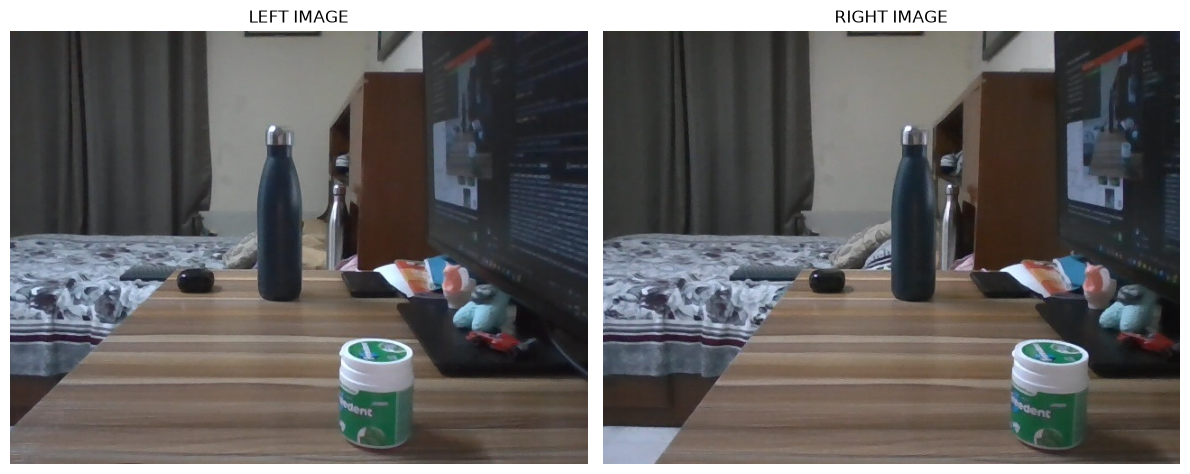


Calculating disparity map...


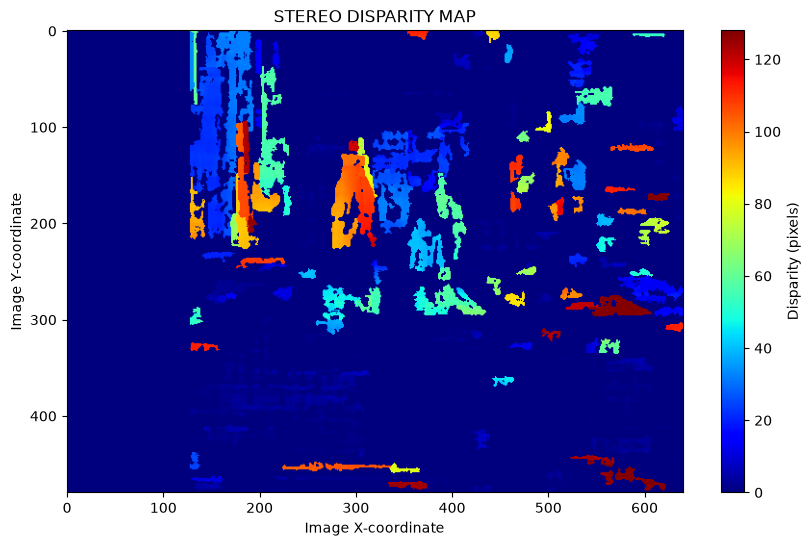

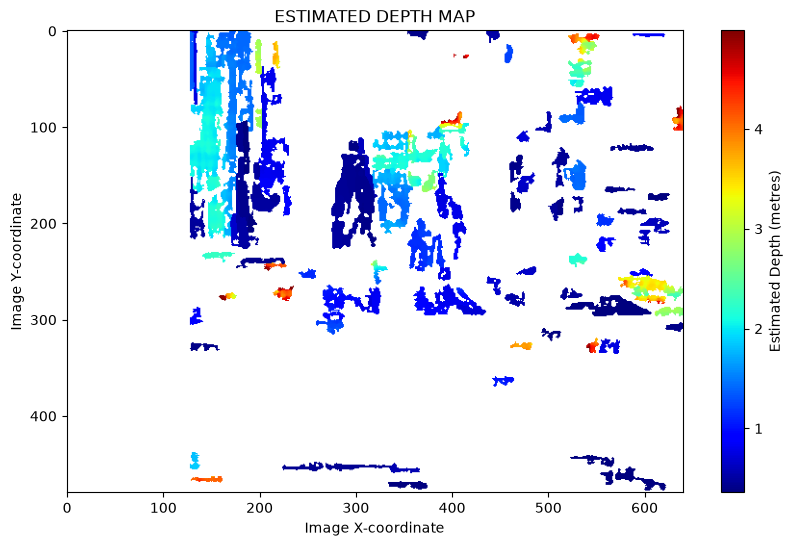


INTERACTIVE DEPTH MEASUREMENT

Click on an object in the disparity map.
The program will estimate its distance.



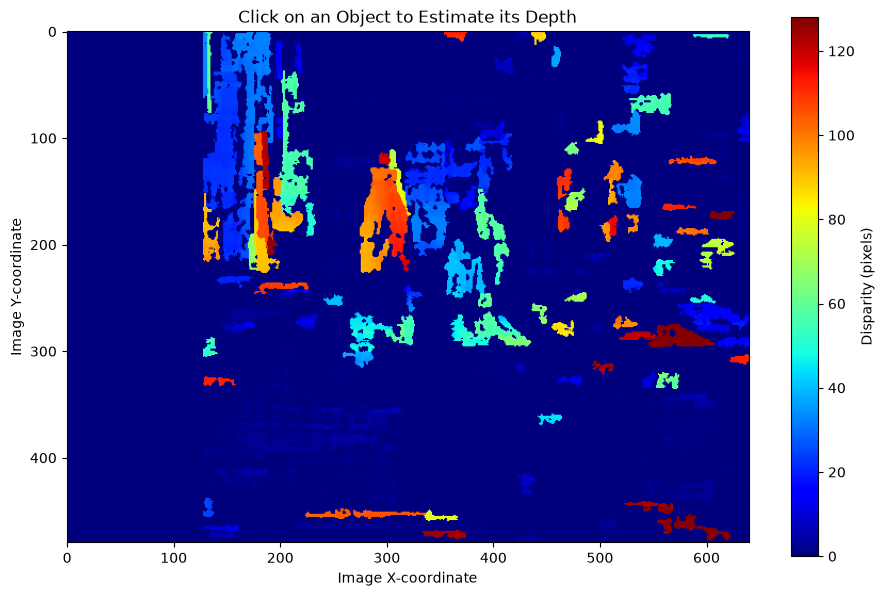


EXAMPLE DEPTH CALCULATIONS
Disparity: 20 pixels  -> Depth: 2.27 m
Disparity: 30 pixels  -> Depth: 1.52 m
Disparity: 40 pixels  -> Depth: 1.14 m
Disparity: 50 pixels  -> Depth: 0.91 m
Disparity: 60 pixels  -> Depth: 0.76 m

Disparity map saved as:
disparity_map.jpg

EXPERIMENT COMPLETED

Parameters used:
Baseline = 0.065 m
Focal length = 700.0 pixels

NOTE: The calculated depth is approximate because the focal length has been assumed.
For accurate measurements, perform camera calibration and stereo rectification.


In [1]:
# ============================================================
# COMPUTER VISION PRACTICAL
# Stereo Vision for Depth Estimation Using One Laptop Camera
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# PARAMETERS
# ============================================================

# Baseline: distance between LEFT and RIGHT camera positions
# 6.5 cm = 0.065 m
BASELINE = 0.065

# Approximate focal length in pixels.
# Replace this with the calibrated focal length if available.
FOCAL_LENGTH = 700.0


# ============================================================
# STEP 1: CAPTURE LEFT AND RIGHT IMAGES
# ============================================================

print("==============================================")
print("     STEREO VISION DEPTH ESTIMATION")
print("==============================================")
print()
print("Instructions:")
print("1. Position the laptop at the LEFT position.")
print("2. Press L to capture the LEFT image.")
print("3. Move the laptop 6.5 cm horizontally RIGHT.")
print("4. Do NOT rotate or tilt the laptop.")
print("5. Press R to capture the RIGHT image.")
print("6. Press Q when both images have been captured.")
print()

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("ERROR: Camera could not be opened.")
    exit()

left_captured = False
right_captured = False

while True:

    ret, frame = cap.read()

    if not ret:
        print("ERROR: Could not read camera frame.")
        break

    # Display instructions on camera window
    display_frame = frame.copy()

    cv2.putText(
        display_frame,
        "L = Left | R = Right | Q = Continue",
        (20, 30),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (0, 255, 0),
        2
    )

    cv2.imshow("Stereo Image Capture", display_frame)

    key = cv2.waitKey(1) & 0xFF

    # Capture LEFT image
    if key == ord('l'):

        cv2.imwrite("left.jpg", frame)

        left_captured = True

        print()
        print("LEFT image captured.")
        print("Now move the laptop 6.5 cm horizontally RIGHT.")
        print("Keep the camera at the same height and orientation.")
        print("Then press R.")

    # Capture RIGHT image
    elif key == ord('r'):

        if not left_captured:
            print("Capture the LEFT image first!")

        else:
            cv2.imwrite("right.jpg", frame)

            right_captured = True

            print()
            print("RIGHT image captured.")

    # Continue
    elif key == ord('q'):

        if left_captured and right_captured:
            break

        else:
            print("Please capture BOTH left and right images first.")


cap.release()
cv2.destroyAllWindows()


# ============================================================
# STEP 2: LOAD THE STEREO IMAGES
# ============================================================

left = cv2.imread("left.jpg")
right = cv2.imread("right.jpg")

if left is None or right is None:
    print("ERROR: Images could not be loaded.")
    exit()

print()
print("Stereo images successfully loaded.")


# ============================================================
# STEP 3: CHECK IMAGE DIMENSIONS
# ============================================================

if left.shape != right.shape:

    print("Image sizes are different.")
    print("Resizing RIGHT image...")

    right = cv2.resize(
        right,
        (left.shape[1], left.shape[0])
    )


# ============================================================
# STEP 4: DISPLAY LEFT AND RIGHT IMAGES
# ============================================================

left_rgb = cv2.cvtColor(left, cv2.COLOR_BGR2RGB)
right_rgb = cv2.cvtColor(right, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(left_rgb)
plt.title("LEFT IMAGE")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(right_rgb)
plt.title("RIGHT IMAGE")
plt.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# STEP 5: CONVERT IMAGES TO GRAYSCALE
# ============================================================

left_gray = cv2.cvtColor(
    left,
    cv2.COLOR_BGR2GRAY
)

right_gray = cv2.cvtColor(
    right,
    cv2.COLOR_BGR2GRAY
)


# ============================================================
# STEP 6: CREATE STEREO SGBM MATCHER
# ============================================================

# Number of disparities MUST be divisible by 16.
num_disparities = 16 * 8       # 128 disparities

block_size = 5

stereo = cv2.StereoSGBM_create(

    minDisparity=0,

    numDisparities=num_disparities,

    blockSize=block_size,

    P1=8 * block_size ** 2,

    P2=32 * block_size ** 2,

    uniquenessRatio=10,

    speckleWindowSize=100,

    speckleRange=2,

    disp12MaxDiff=1,

    mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY
)


# ============================================================
# STEP 7: CALCULATE DISPARITY
# ============================================================

print()
print("Calculating disparity map...")

disparity = stereo.compute(
    left_gray,
    right_gray
).astype(np.float32) / 16.0


# ============================================================
# STEP 8: DISPLAY DISPARITY MAP
# ============================================================

plt.figure(figsize=(10, 6))

plt.imshow(
    disparity,
    cmap="jet",
    vmin=0,
    vmax=num_disparities
)

plt.colorbar(
    label="Disparity (pixels)"
)

plt.title("STEREO DISPARITY MAP")

plt.xlabel("Image X-coordinate")
plt.ylabel("Image Y-coordinate")

plt.show()


# ============================================================
# STEP 9: CALCULATE DEPTH MAP
# ============================================================

# Stereo depth equation:
#
#             f × B
#       Z = ---------
#               d
#
# Z = depth (metres)
# f = focal length (pixels)
# B = baseline (metres)
# d = disparity (pixels)


depth = np.full(
    disparity.shape,
    np.nan,
    dtype=np.float32
)

# Only positive disparities are valid
valid = disparity > 0

depth[valid] = (
    FOCAL_LENGTH * BASELINE
) / disparity[valid]


# ============================================================
# STEP 10: LIMIT DEPTH FOR VISUALISATION
# ============================================================

# Ignore extremely large distances when displaying the map
max_depth = 5.0

depth_display = depth.copy()

depth_display[
    depth_display > max_depth
] = np.nan


# ============================================================
# STEP 11: DISPLAY DEPTH MAP
# ============================================================

plt.figure(figsize=(10, 6))

depth_image = plt.imshow(
    depth_display,
    cmap="jet"
)

plt.colorbar(
    depth_image,
    label="Estimated Depth (metres)"
)

plt.title("ESTIMATED DEPTH MAP")

plt.xlabel("Image X-coordinate")
plt.ylabel("Image Y-coordinate")

plt.show()


# ============================================================
# STEP 12: INTERACTIVE DEPTH MEASUREMENT
# ============================================================

print()
print("==============================================")
print("INTERACTIVE DEPTH MEASUREMENT")
print("==============================================")
print()
print("Click on an object in the disparity map.")
print("The program will estimate its distance.")
print()


fig, ax = plt.subplots(figsize=(11, 7))

image = ax.imshow(
    disparity,
    cmap="jet",
    vmin=0,
    vmax=num_disparities
)

plt.colorbar(
    image,
    ax=ax,
    label="Disparity (pixels)"
)

ax.set_title(
    "Click on an Object to Estimate its Depth"
)

ax.set_xlabel("Image X-coordinate")
ax.set_ylabel("Image Y-coordinate")


# ============================================================
# FUNCTION EXECUTED WHEN USER CLICKS
# ============================================================

def onclick(event):

    # Ignore clicks outside image
    if event.xdata is None or event.ydata is None:
        return

    x = int(event.xdata)
    y = int(event.ydata)

    # Check image boundaries
    if (
        x < 0 or
        y < 0 or
        x >= disparity.shape[1] or
        y >= disparity.shape[0]
    ):
        return

    d = disparity[y, x]

    print()
    print("----------------------------------")
    print("Selected pixel:")
    print("X =", x)
    print("Y =", y)

    # Valid disparity
    if d > 0:

        Z = (
            FOCAL_LENGTH *
            BASELINE
        ) / d

        print(
            "Disparity =",
            round(float(d), 2),
            "pixels"
        )

        print(
            "Estimated Depth =",
            round(float(Z), 2),
            "metres"
        )

        # Mark selected point
        ax.plot(
            x,
            y,
            marker="x",
            markersize=10
        )

        # Display depth value
        ax.text(
            x + 10,
            y,
            f"{Z:.2f} m",
            fontsize=10,
            bbox=dict(
                boxstyle="round",
                alpha=0.7
            )
        )

        fig.canvas.draw()

    else:

        print(
            "Invalid disparity at this point."
        )

        print(
            "Try clicking on a textured "
            "part of the object."
        )


# Connect mouse click event
fig.canvas.mpl_connect(
    "button_press_event",
    onclick
)

plt.show()


# ============================================================
# STEP 13: EXAMPLE DEPTH CALCULATIONS
# ============================================================

print()
print("==============================================")
print("EXAMPLE DEPTH CALCULATIONS")
print("==============================================")

example_disparities = [
    20,
    30,
    40,
    50,
    60
]

for d in example_disparities:

    Z = (
        FOCAL_LENGTH *
        BASELINE
    ) / d

    print(
        "Disparity:",
        d,
        "pixels",
        " -> Depth:",
        round(Z, 2),
        "m"
    )


# ============================================================
# STEP 14: SAVE RESULTS
# ============================================================

# Normalize disparity for saving as image
valid_disp = np.maximum(
    disparity,
    0
)

disp_normalized = cv2.normalize(
    valid_disp,
    None,
    0,
    255,
    cv2.NORM_MINMAX
)

disp_normalized = np.uint8(
    disp_normalized
)

cv2.imwrite(
    "disparity_map.jpg",
    disp_normalized
)

print()
print("Disparity map saved as:")
print("disparity_map.jpg")


# ============================================================
# END OF PROGRAM
# ============================================================

print()
print("==============================================")
print("EXPERIMENT COMPLETED")
print("==============================================")

print()
print("Parameters used:")

print(
    "Baseline =",
    BASELINE,
    "m"
)

print(
    "Focal length =",
    FOCAL_LENGTH,
    "pixels"
)

print()
print(
    "NOTE: The calculated depth is approximate "
    "because the focal length has been assumed."
)

print(
    "For accurate measurements, perform camera "
    "calibration and stereo rectification."
)